# Machine Learning for Regression: A Beginner's Step-by-Step Notebook

*Built from the "Car Price Prediction" lessons (ML Zoomcamp, Session 2). Every step is explained in plain language, followed by code you can run.*

## How to use this notebook

- Run the cells **from top to bottom, in order**. Later cells depend on variables created earlier.
- Every step has the same shape: **Goal → Idea → Code → What to remember → Common confusion**.
- New word? Check the **Glossary** right below.
- Some cells are *deliberately* broken (to show a problem). They are labelled **"expected to fail"** or **"this breaks the model"**, and the next cells explain and fix them.
- If you restart the kernel, run everything from the top again.

## Table of contents

- Part 0: Glossary and prerequisites
- Part 1: The big picture
- Step 1: Data preparation
- Step 2: Exploratory data analysis (EDA)
- Step 3: The validation framework (train / validation / test)
- Step 4: Linear regression for one car
- Step 5: Linear regression in vector and matrix form
- Step 6: Training: where do the weights come from? (Normal equation)
- Step 7: The baseline model
- Step 8: RMSE: one number for "how good is my model?"
- Step 9: Computing RMSE on validation data
- Step 10: Feature engineering
- Step 11: Categorical variables
- Step 12: Regularization (fixing the broken model)
- Step 13: Tuning the model
- Step 14: The final model and using it
- Part 15: Cheat sheets
- Part 16: Common confusions (FAQ)
- Part 17: Self-test questions (with answers)
- Part 18: Practice ideas

---
## Part 0: Glossary and prerequisites

### Words you will see everywhere

| Term | Plain-English meaning | Example in this project |
|---|---|---|
| **Machine learning (ML)** | Letting a computer find patterns in data instead of writing the rules by hand. | The computer learns how car characteristics relate to price. |
| **Regression** | An ML problem where the thing we predict is a **number**. | Predicting a price. |
| **Classification** | An ML problem where we predict a **category** (spam / not spam). Comes in the next session. | n/a |
| **Observation / record / example** | One row of the data. | One car. |
| **Feature** | One input characteristic (a column used to predict). | Horsepower, age, make. |
| **Target** (`y`) | The thing we want to predict. | The price (MSRP). |
| **MSRP** | Manufacturer's Suggested Retail Price. | The price column. |
| **Model** (`g`) | A function that takes features and outputs a prediction. | Linear regression. |
| **Weights** (`w`) | Numbers inside the model saying how much each feature matters. They are what the model *learns*. | "Each extra horsepower adds 0.01 to the prediction." |
| **Bias term** (`w0`) | The base prediction before any feature is considered. | 7.17 in our first example. |
| **Training** | Finding good weights from data. | Using the normal equation. |
| **Validation** | Checking the model on data it did **not** train on. | The validation set. |
| **Hyperparameter** | A setting *we* choose (not learned from data). | The regularization number `r`. |
| **Baseline model** | A simple first model; its score is the reference to beat. | Model with 5 numeric features. |
| **Overfitting** | The model memorizes training data and fails on new data. | Why we validate. |

### Vectors and matrices (the only math you need)

- A **vector** is a list of numbers: `[453, 11, 86]`.
- A **matrix** is a table of numbers. Our **feature matrix `X`** has one row per car and one column per feature.
- **Shape** is *rows × columns*. A matrix with 3 rows and 4 columns is "3×4".
- **Transpose** (`Xᵀ`, in code `X.T`): flip rows and columns. A 3×4 matrix becomes 4×3.
- **Dot product** of two same-length vectors: multiply position by position, then add everything up.
  `[1, 2, 3] · [4, 5, 6] = 1·4 + 2·5 + 3·6 = 32`
- **Matrix-vector multiplication** (`X.dot(w)`): the dot product of **each row** of `X` with `w`. One number per row.
- **Identity matrix `I`**: a square matrix with 1s on the diagonal and 0s elsewhere. Multiplying by it changes nothing (like multiplying a number by 1). In NumPy: `np.eye(3)`.
- **Inverse `A⁻¹`** of a square matrix `A`: the matrix with `A⁻¹ · A = I`. Think "1 divided by A". Only some square matrices have one.

Let's try these in code:

In [1]:
import numpy as np

a = np.array([1, 2, 3])
b = np.array([4, 5, 6])
print("dot product:", a.dot(b))            # 1*4 + 2*5 + 3*6 = 32

M = np.array([[1, 2, 3, 4],
              [5, 6, 7, 8],
              [9, 10, 11, 12]])
print("shape of M:", M.shape)               # (3, 4)  -> 3 rows, 4 columns
print("shape of M.T:", M.T.shape)           # (4, 3)

w_demo = np.array([1, 0, 0, 1])
print("M.dot(w_demo):", M.dot(w_demo))      # one number per row of M

print("identity matrix:\n", np.eye(3))

dot product: 32
shape of M: (3, 4)
shape of M.T: (4, 3)
M.dot(w_demo): [ 5 13 21]
identity matrix:
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


### Python tools used

- **pandas** (`pd`): tables (`DataFrame`) and columns (`Series`).
- **NumPy** (`np`): fast math on arrays, matrices and vectors.
- **matplotlib / seaborn** (`plt`, `sns`): charts.

Imports used throughout the notebook:

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
# ^ makes plots show up inside the notebook

---
## Part 1: The big picture

### The scenario

A person wants to sell a car on a classified-ads website. The site asks for a price, but the seller may not know what the car is worth. We want the seller to describe the car and have our **model suggest a price**.

### The data

A Kaggle dataset of about **11,914 cars**. Each row is one car. Columns include make, model, year, fuel type, horsepower, cylinders, transmission, doors, MPG, popularity... and **MSRP (the price)**.

### The central idea in one line

```
g(X) ≈ y
```

- `X` = the feature matrix (all cars, all characteristics)
- `g` = our model (linear regression)
- `y` = the true prices
- `≈` = "as close as possible"

> **Learning = finding the model `g` whose predictions are as close as possible to the real prices.**

### The project roadmap

```
Get data → Clean it → Explore it → Split it (train/val/test)
   → Linear regression (idea) → Train it (normal equation)
   → Baseline model → Measure with RMSE
   → Improve: feature engineering → categorical variables
   → Fix instability: regularization → Tune → Final model → Use it
```

---
## Step 1: Data preparation

**Goal:** Load the data and make names and values consistent so they are easy to work with.

### 1.1 Download and load

`wget` downloads a file from a URL. In a notebook, a line starting with `!` runs a terminal command. (You can also just download `data.csv` in your browser and put it next to this notebook.)

In [3]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-02-car-price/data.csv'
!wget -q -nc $data
# -q = quiet, -nc = don't download again if the file already exists

In [4]:
df = pd.read_csv('data.csv')   # reads the CSV into a DataFrame
df.head()                      # shows the first 5 rows

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


Every row is one car; every column is one characteristic. **`MSRP` is the price we want to predict.**

### 1.2 Clean the column names

The names are inconsistent: `Make` (capital), `Engine Fuel Type` (spaces), `Driven_Wheels` (underscore).

**Why spaces are a problem:** with a column called `Transmission Type`, you can't write `df.Transmission Type` (syntax error). You'd have to write `df['Transmission Type']`. Simple names (lowercase, underscores) let you use the easy dot notation.

Read the next line from left to right:

1. `df.columns` - the list of column names.
2. `.str.lower()` - lowercase each name.
3. `.str.replace(' ', '_')` - swap spaces for underscores.
4. `df.columns = ...` - **save the result back**. (Without the assignment nothing changes; the line would only *show* the cleaned names.)

In [5]:
df.columns = df.columns.str.lower().str.replace(' ', '_')
df.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'msrp'],
      dtype='str')

### 1.3 Clean the values in text columns

We do the same for the *values* inside text columns (`BMW` → `bmw`, `Premium Unleaded` → `premium_unleaded`).

First, find which columns hold text. In pandas, text columns have the type **`object`**.

In [6]:
df.dtypes

make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors      float64
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
msrp                   int64
dtype: object

How the next line works:

- `df.dtypes == 'object'` → True/False for each column.
- `df.dtypes[ ... ]` → keep only the `True` ones.
- `.index` → the **names** of those columns (we don't need the values; they are all "object").
- `list(...)` → a normal Python list (only for neatness).

In [7]:
strings = list(df.dtypes[df.dtypes == 'object'].index)
strings

[]

In [8]:
for col in strings:
    df[col] = df[col].str.lower().str.replace(' ', '_')

df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


### Remember (Step 1)

- `pd.read_csv()`, `df.head()`, `df.columns`, `df.dtypes`
- `.str.lower()` and `.str.replace()` work on columns of text.
- Cleaning changes the format, not the information.

---
## Step 2: Exploratory data analysis (EDA)

**Goal:** Get a feel for the data *before* modelling: what the columns contain, what the target looks like, and what is missing.

### 2.1 Look at every column

- `unique()` = the distinct values in a column. `nunique()` = how many distinct values.
- We print the first 5 distinct values and the count for each column.

In [9]:
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])   # first 5 distinct values
    print(df[col].nunique())      # how many distinct values
    print()

make
<StringArray>
['BMW', 'Audi', 'FIAT', 'Mercedes-Benz', 'Chrysler']
Length: 5, dtype: str


48

model
<StringArray>
['1 Series M', '1 Series', '100', '124 Spider', '190-Class']
Length: 5, dtype: str
915

year
[2011 2012 2013 1992 1993]
28

engine_fuel_type
<StringArray>
[   'premium unleaded (required)',               'regular unleaded',
 'premium unleaded (recommended)',       'flex-fuel (unleaded/E85)',
                         'diesel']
Length: 5, dtype: str
10

engine_hp
[335. 300. 230. 320. 172.]
356

engine_cylinders
[ 6.  4.  5.  8. 12.]
9

transmission_type
<StringArray>
['MANUAL', 'AUTOMATIC', 'AUTOMATED_MANUAL', 'DIRECT_DRIVE', 'UNKNOWN']
Length: 5, dtype: str
5

driven_wheels
<StringArray>
['rear wheel drive', 'front wheel drive', 'all wheel drive',
 'four wheel drive']
Length: 4, dtype: str
4

number_of_doors
[ 2.  4.  3. nan]
3

market_category
<StringArray>
['Factory Tuner,Luxury,High-Performance',
                    'Luxury,Performance',
               'Luxury,High-Performance',
                                'Luxury',
                           'Performance'

What you learn: `make` has 48 values, `model` 914, `year` 28, `engine_fuel_type` 10, and so on. `popularity` is the number of Twitter mentions of a car (more mentions = more popular). `highway_mpg` / `city_mpg` are miles per gallon.

### 2.2 Look at the price (the target)

A column of numbers doesn't show the big picture, so we **plot a histogram**: the value range is split into buckets ("bins"), and each bar's height is how many values fall in that bucket.

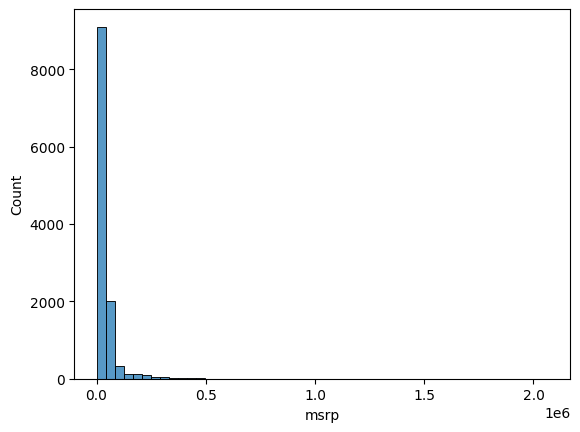

In [10]:
sns.histplot(df.msrp, bins=50)
plt.show()

- `1e6` on the x-axis means 1,000,000 (scientific notation).
- Almost all cars are cheap (left side) and a few are extremely expensive (up to ~2 million). This shape is called a **long-tail distribution**. Prices commonly look like this: most things are affordable, a few are luxury.

Zoom in on cheaper cars to see the shape better:

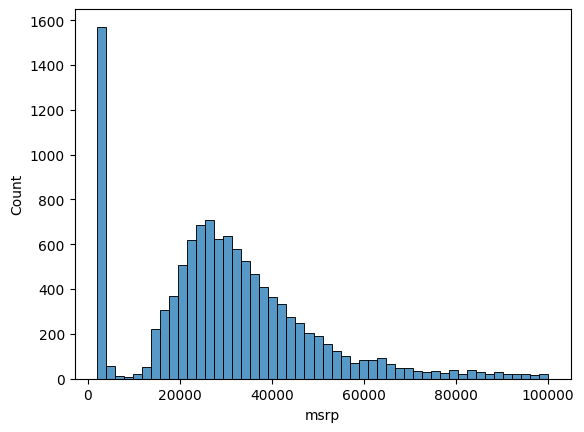

In [11]:
sns.histplot(df.msrp[df.msrp < 100000], bins=50)
plt.show()

(There is an odd peak at 1,000, probably the minimum price the website accepts.)

### 2.3 Why we shrink the long tail with a logarithm

**Problem:** a long tail confuses the model. A few huge values dominate the errors and distort what the model learns.

**Fix:** apply a **logarithm** to the price. The log "squashes" large numbers much more than small ones. A jump from 1,000 to 1,000,000 (×1000) becomes just 6.9 → 13.8.

**Why `log1p` and not `log`?** `log(0)` doesn't exist (NumPy gives `-inf` and a warning). `np.log1p(x)` means `log(x + 1)`, so zero is safe. Our prices are always ≥ 1,000 so it wouldn't matter here, but it's a safe habit.

In [12]:
# plain log of zero -> -inf plus a warning
print(np.log([0 + 1, 1 + 1, 10 + 1, 1000 + 1, 100000 + 1]))

# log1p handles zero safely
print(np.log1p([0, 1, 10, 1000, 100000]))

# how the log squashes big numbers
for price in [1000, 15000, 100000, 1000000]:
    print(f"price {price:>9,}  ->  log1p = {np.log1p(price):.2f}")

[ 0.          0.69314718  2.39789527  6.90875478 11.51293546]
[ 0.          0.69314718  2.39789527  6.90875478 11.51293546]
price     1,000  ->  log1p = 6.91
price    15,000  ->  log1p = 9.62
price   100,000  ->  log1p = 11.51
price 1,000,000  ->  log1p = 13.82


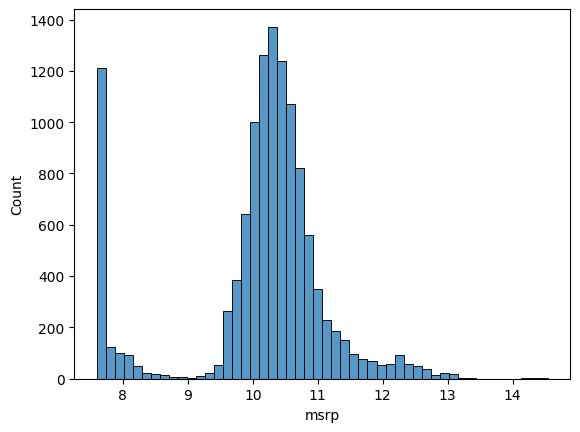

In [13]:
price_logs = np.log1p(df.msrp)
sns.histplot(price_logs, bins=50)
plt.show()

The tail is gone and the histogram looks like a **bell curve** (a *normal distribution*). Models work much better when the target has this shape.

> **Important consequence:** from now on the model predicts the **log of the price**. To get dollars back we undo the log with `np.expm1` (the inverse of `log1p`). We'll do this at the end.

### 2.4 Missing values

When pandas has no value, it shows `NaN` ("not a number").

- `df.isnull()` → a table of True/False ("is this cell missing?").
- `.sum()` → counts the Trues per column (True counts as 1).

In [14]:
df.isnull().sum()

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

`engine_hp` has 69 missing values, `engine_cylinders` 30, `number_of_doors` 6, `engine_fuel_type` 3, and `market_category` 3,742. We must deal with this before training.

### Remember (Step 2)

- EDA = look before you model.
- Long-tail target → apply `np.log1p`.
- Check missing values with `df.isnull().sum()`.

---
## Step 3: The validation framework (train / validation / test)

**Goal:** split the data so we can honestly measure how the model behaves on data it has never seen.

### 3.1 Why split?

Imagine studying for an exam using the *exact* exam questions. You would score perfectly, which proves nothing. A model is the same: if we test it on the data it trained on, the score is flattering and misleading. So we split the data into three parts:

| Part | Share | Used for |
|---|---|---|
| **Train** | 60% | Learn the weights. |
| **Validation** | 20% | Compare models and choose settings (e.g. `r`). |
| **Test** | 20% | Final check, used **once, at the very end**. |

From each part we build a feature matrix `X` and a target vector `y`.

### 3.2 Compute the sizes

- `int()` cuts off the fraction (we need whole rows).
- `n_train` is computed by **subtraction** instead of `int(n * 0.6)`. Rounding could make the three sizes add up to *less* than `n`, silently dropping a few rows. Subtracting guarantees every row is used.

In [15]:
n = len(df)

n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

n, n_val, n_test, n_train

(11914, 2382, 2382, 7150)

### 3.3 Why you must shuffle

`iloc` selects rows **by position** (`df.iloc[:10]` = the first ten rows). The simplest split would be to cut the table in sequential chunks. But our data is **sorted by make**, so look what happens:

In [16]:
# A bad, sequential split (for demonstration only - we do not keep it)
bad_val = df.iloc[:n_val]
bad_train = df.iloc[n_val + n_test:]

print("makes in the 'validation' part:", bad_val.make.nunique())
print("is 'bmw' in the 'train' part? ", 'bmw' in set(bad_train.make))
print(bad_val.make.value_counts().head())

makes in the 'validation' part: 35
is 'bmw' in the 'train' part?  False
make
BMW           224
Volkswagen    184
Audi          178
Mazda         174
Nissan        165
Name: count, dtype: int64


Validation holds makes that training barely sees (or never sees). So we **shuffle first**:

- `np.arange(n)` makes the numbers `0 … n-1`.
- `np.random.shuffle(idx)` shuffles those numbers in place.
- `iloc` with shuffled positions returns shuffled rows.
- `np.random.seed(2)` fixes the "random" order so your results match everyone else's (**reproducibility**).

In [17]:
np.random.seed(2)

idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

len(df_train), len(df_val), len(df_test)

(7150, 2382, 2382)

### 3.4 Reset the index

After shuffling, the row labels are scrambled (2735, 6720, ...). We don't need them. `drop=True` means "throw the old index away" (don't keep it as a new column).

In [18]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

df_train.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,Chevrolet,Cobalt,2008,regular unleaded,148.0,4.0,MANUAL,front wheel drive,2.0,NaN,Compact,Coupe,33,24,1385,14410
1,Toyota,Matrix,2012,regular unleaded,132.0,4.0,AUTOMATIC,front wheel drive,4.0,Hatchback,Compact,4dr Hatchback,32,25,2031,19685
2,Subaru,Impreza,2016,regular unleaded,148.0,4.0,AUTOMATIC,all wheel drive,4.0,Hatchback,Compact,4dr Hatchback,37,28,640,19795
3,Volkswagen,Vanagon,1991,regular unleaded,90.0,4.0,MANUAL,rear wheel drive,3.0,NaN,Large,Passenger Minivan,18,16,873,2000
4,Ford,F-150,2017,flex-fuel (unleaded/E85),385.0,8.0,AUTOMATIC,four wheel drive,4.0,Flex Fuel,Large,Crew Cab Pickup,21,15,5657,56260


### 3.5 Create `y` and remove `msrp` from the features

- `.values` gives a plain NumPy array (we don't need pandas extras for `y`).
- We apply `log1p` here (the log transform from Step 2).
- **Why delete `msrp` from the data frames?** To avoid *target leakage*: if the price accidentally ends up in the features, the model uses the price to predict the price and looks perfect, and you waste hours finding out why. Remove the target as soon as you've extracted it.

In [19]:
y_train = np.log1p(df_train.msrp.values)
y_val = np.log1p(df_val.msrp.values)
y_test = np.log1p(df_test.msrp.values)

del df_train['msrp']
del df_val['msrp']
del df_test['msrp']

print(y_train[:5])
print('msrp' in df_train.columns)   # False: it's gone

[ 9.57574708  9.887663    9.89323518  7.60140233 10.93775686]
False


### Remember (Step 3)

- Split 60/20/20, **shuffle**, set a **seed**, reset the index.
- Make `y` from the log of the price; **delete the target from the features**.
- The test set stays untouched until the very end.

---
## Step 4: Linear regression for one car

**Goal:** understand what linear regression actually computes, using a single car.

### 4.1 The idea

Linear regression predicts a number as **a base value plus each feature multiplied by a weight**:

```
prediction = w0 + w1·x1 + w2·x2 + w3·x3 + ...
```

- `w0` (bias): what we'd predict knowing nothing about the car.
- `wj`: how much feature `j` pushes the prediction up or down, per unit.
- `xj`: the value of feature `j` for this car.

In math notation for car number `i` with `n` features:

```
g(xi) = w0 + Σ (j = 1 to n)  wj · xij
```

`Σ` just means "add up". `xij` means "feature `j` of car `i`".

### 4.2 A worked example

Take one car from the training data (row 10): a Rolls-Royce Phantom from 2015. We use only three features:

| Feature | Value |
|---|---|
| Engine horsepower | 453 |
| City MPG | 11 |
| Popularity | 86 |

The weights below are **invented by us for now**. Step 6 shows how real ones are found.

In [20]:
df_train.iloc[[10]][['make', 'model', 'year', 'engine_hp', 'city_mpg', 'popularity']]

,make,model,year,engine_hp,city_mpg,popularity
10,Rolls-Royce,Phantom Drophead Coupe,2015,453.0,11,86


In [21]:
xi = [453, 11, 86]
w0 = 7.17
w = [0.01, 0.04, 0.002]

In [22]:
def linear_regression(xi):
    n = len(xi)

    pred = w0                          # start from the bias

    for j in range(n):
        pred = pred + w[j] * xi[j]     # add feature x weight

    return pred

linear_regression(xi)

12.312

By hand:

```
7.17 + 453·0.01 + 11·0.04 + 86·0.002
= 7.17 + 4.53 + 0.44 + 0.172
= 12.312
```

How to read each piece:

- **7.17**: the starting prediction.
- **453 · 0.01 = 4.53**: each horsepower adds 0.01; this car has many, so it adds a lot.
- **11 · 0.04 = 0.44**: a bit more for a high-consumption (fancier/bigger) car.
- **86 · 0.002 = 0.172**: popularity barely matters because its weight is tiny.

> *Python note:* the formula's `j` goes from 1 to n, but Python counts from 0, so the loop is `range(n)` = 0 … n-1. Same thing.

### 4.3 From log-price back to dollars

12.312 is **not** dollars. Our target was `log1p(price)`, so the output is on the log scale. Undo it with `np.expm1`.

In [23]:
print(np.expm1(12.312))               # about 222,347 -> roughly $222,000

# expm1 and log1p are exact opposites
print(np.log1p(np.expm1(12.312)))     # back to 12.312

222347.2221101062
12.312


### Common confusion (Step 4)

- **Can weights be negative?** Yes. A negative weight means "as this feature increases, the predicted price goes down" (e.g. age).
- **What does the size of a weight mean?** It is the effect of **one unit** of that feature. Features on big scales (like popularity ≈ 2000) can have tiny weights and still matter, so don't compare weights across features with different scales.

---
## Step 5: Linear regression in vector and matrix form

**Goal:** rewrite the same formula in a shorter form, then compute predictions for **all cars at once**.

### 5.1 The sum is a dot product

`Σ wj · xij` means "multiply feature and weight pairs, then add" = a **dot product**. So:

```
g(xi) = w0 + xiᵀ · w
```

In [24]:
def dot(xi, w):
    n = len(xi)

    res = 0.0

    for j in range(n):
        res = res + xi[j] * w[j]

    return res


def linear_regression(xi):
    return w0 + dot(xi, w)


linear_regression(xi)    # same 12.312

12.312000000000001

### 5.2 The "fictional feature" trick (absorbing the bias)

`w0` sits alone, which is awkward. Trick: pretend every car has an extra feature `xi0` that is **always 1**. Then

```
w  = [w0, w1, w2, w3]        <- now n+1 numbers
xi = [ 1, xi1, xi2, xi3]     <- 1 prepended
```

`w0 · 1` is just `w0`, so **one dot product does everything**. In Python, `list + list` joins the lists, so `[w0] + w` prepends `w0`.

In [25]:
w_new = [w0] + w
print(w_new)                   # [7.17, 0.01, 0.04, 0.002]


def linear_regression(xi):
    xi = [1] + xi              # prepend the fictional feature
    return dot(xi, w_new)


linear_regression(xi)          # still 12.312

[7.17, 0.01, 0.04, 0.002]


12.312

### 5.3 All cars at once: matrix-vector multiplication

Stack cars into a matrix `X`; each row starts with the fictional `1`. Then `X.dot(w_new)` does the dot product of **every row** with the weights and returns one prediction per car. In math: **`Xw ≈ y`**.

Shapes: `X` is `m × (n+1)`, `w` has `n+1` numbers, the result has `m` numbers (one per car).

In [26]:
x1 = [1, 148, 24, 1385]
x2 = [1, 132, 25, 2031]
x10 = [1, 453, 11, 86]

X_three = np.array([x1, x2, x10])
print(X_three.shape)      # (3, 4)
X_three

(3, 4)


array([[   1,  148,   24, 1385],
       [   1,  132,   25, 2031],
       [   1,  453,   11,   86]])

In [27]:
def linear_regression(X):
    return X.dot(w_new)

linear_regression(X_three)    # array([12.38 , 13.552, 12.312])

array([12.38 , 13.552, 12.312])

### Remember (Step 5)

- Single car: `w0 + xᵀw`
- All cars: `X · w` (with a column of ones in `X`)
- The next question: **where do the weights `w` come from?**

---
## Step 6: Training: where do the weights come from? (Normal equation)

**Goal:** find the weights `w` automatically from data.

### 6.1 The wish

We want `Xw = y` (predictions exactly equal to real prices). Solving for `w` would be easy **if `X` had an inverse**:

```
Xw = y   →   X⁻¹Xw = X⁻¹y   →   Iw = X⁻¹y   →   w = X⁻¹y
```

**But** `X` is **rectangular** (thousands of rows, a few columns), and only **square** matrices can have inverses. Also, real data never lines up perfectly on a line, so an exact solution does not exist.

### 6.2 The workaround: the Gram matrix

We can't get the exact answer, but we can get the **closest possible** one. Multiply both sides by `Xᵀ`:

```
XᵀXw = Xᵀy
```

`XᵀX` is called the **Gram matrix**. Unlike `X` it is **square**: `(n+1) × (n+1)`. Now invert it:

```
(XᵀX)⁻¹ XᵀX w = (XᵀX)⁻¹ Xᵀ y
                w = (XᵀX)⁻¹ Xᵀ y          <- the NORMAL EQUATION
```

This `w` isn't an exact solution, but it is the **best approximate one** (it minimizes the squared errors; the full proof is in *The Elements of Statistical Learning*, and you don't need it to use the formula).

Shape check, with `m` cars and `n+1` columns:

```
(XᵀX)⁻¹  : (n+1) × (n+1)
Xᵀ       : (n+1) × m
y        : m
result w : n+1        <- one weight per column, including the bias
```

> **Machine learning is not magic here: training is just evaluating one formula.**

### 6.3 Implementing it step by step on a toy example

Nine made-up cars with three features, and nine made-up prices.

In [28]:
X_toy = np.array([
    [148, 24, 1385],
    [132, 25, 2031],
    [453, 11, 86],
    [158, 24, 185],
    [172, 25, 201],
    [413, 11, 86],
    [38, 54, 185],
    [142, 25, 431],
    [453, 31, 86],
])

y_toy = [100, 200, 150, 250, 100, 200, 150, 250, 120]

XTX = X_toy.T.dot(X_toy)            # Gram matrix (3 x 3)
XTX_inv = np.linalg.inv(XTX)        # its inverse

# Sanity check: matrix x its inverse should be the identity matrix
XTX.dot(XTX_inv).round(1)

array([[ 1.,  0.,  0.],
       [-0.,  1.,  0.],
       [ 0.,  0.,  1.]])

Ones on the diagonal and (almost) zeros elsewhere. They aren't *exactly* zero because computers store decimals with limited precision, so tiny round-off errors appear. Treat them as zero.

In [29]:
w_full = XTX_inv.dot(X_toy.T).dot(y_toy)     # the normal equation
w_full

array([0.26190562, 3.06101252, 0.03696909])

We forgot the **bias term**. Add a column of ones as the first column (`np.column_stack` puts arrays side by side as columns), then repeat the same steps.

In [30]:
ones = np.ones(X_toy.shape[0])
X_toy_b = np.column_stack([ones, X_toy])

XTX = X_toy_b.T.dot(X_toy_b)
XTX_inv = np.linalg.inv(XTX)
w_full = XTX_inv.dot(X_toy_b.T).dot(y_toy)

w0_toy = w_full[0]       # first element = bias
w_toy = w_full[1:]       # the rest = feature weights
print(w0_toy)
print(w_toy)

300.06776692555627
[-0.22774253 -2.5769413  -0.02301206]


Some weights are negative. That's fine: it means "as this feature grows, the predicted price falls".

### 6.4 Wrap it in a function

The function adds the column of ones itself, so users just pass the plain feature matrix.

In [31]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]


w0_toy, w_toy = train_linear_regression(X_toy, y_toy)
print(w0_toy, w_toy)       # same numbers as above

300.06776692555627 [-0.22774253 -2.5769413  -0.02301206]


### Remember (Step 6)

- Training linear regression = `w = (XᵀX)⁻¹ Xᵀ y`.
- `X.T` is the transpose, `np.linalg.inv` the inverse, `.dot` the multiplication.
- Prediction later: `y_pred = w0 + X.dot(w)`.

---
## Step 7: The baseline model

**Goal:** train a first, simple model on the real car data. Its score becomes the reference to beat.

### 7.1 Choose features

Our linear regression only works with numbers, so we start with five numeric columns.

In [32]:
base = ['engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg', 'popularity']

X_train = df_train[base].values
X_train[:3]

array([[ 148.,    4.,   33.,   24., 1385.],
       [ 132.,    4.,   32.,   25., 2031.],
       [ 148.,    4.,   37.,   28.,  640.]])

### 7.2 First attempt: weights come out as `nan`

Some values in `engine_hp` and `engine_cylinders` are missing (NaN). Any math involving NaN gives NaN.

In [33]:
w0, w = train_linear_regression(X_train, y_train)
print(w0)
print(w)             # all nan

nan
[nan nan nan nan nan]


In [34]:
df_train[base].isnull().sum()

engine_hp           40
engine_cylinders    14
highway_mpg          0
city_mpg             0
popularity           0
dtype: int64

### 7.3 Fill missing values with 0

Is filling with 0 sensible? A car doesn't really have 0 horsepower. But look at what a zero does in the formula:

```
g(xi) = w0 + 0·w1 + xi2·w2  =  w0 + xi2·w2
```

A zero feature **contributes nothing**, so the model effectively ignores that feature for that car. Filling with the column **mean** is often more reasonable, but zero is simple and fine for a baseline.

In [35]:
X_train = df_train[base].fillna(0).values
w0, w = train_linear_regression(X_train, y_train)

print("bias:", w0)         # about 7.93 (on the log scale)
print("weights:", w)

bias: 7.927257388069851
weights: [ 9.70589522e-03 -1.59103494e-01  1.43792133e-02  1.49441072e-02
 -9.06908672e-06]


### 7.4 Predict and compare with the real values

`y_pred = w0 + X_train.dot(w)`: the bias plus the matrix-vector product. We plot predictions (red) over the real values (blue). `alpha` makes the bars transparent so both are visible.

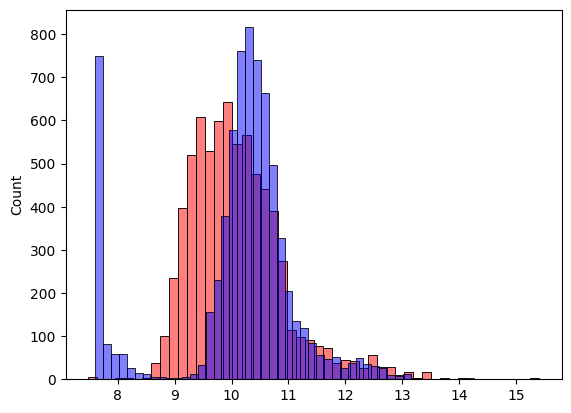

In [36]:
y_pred = w0 + X_train.dot(w)

sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)
plt.show()

The red peak sits left of the blue one: the model often predicts too low. "Looks off" is a subjective judgment though. We need a **number**. That is RMSE.

---
## Step 8: RMSE: one number for "how good is my model?"

**Goal:** measure the average size of the model's errors in a single number.

### 8.1 The formula

```
RMSE = sqrt( (1/m) · Σ (g(xi) − yi)² )
```

Read it from the inside out:

1. `g(xi) − yi`: the **error** for one car (prediction minus real value).
2. `( ... )²`: **square** it. Errors can't cancel each other (+1 and −1 would otherwise average to 0), and big mistakes are punished more.
3. `(1/m) Σ`: **average** over all cars. This is the **MSE** (mean squared error).
4. `sqrt`: the **square root** brings it back to the units of `y`.

### 8.2 A worked example (step by step in code)

In [37]:
y_pred_ex = np.array([10, 9, 11, 10])
y_ex = np.array([9, 9, 10.5, 11.5])

errors = y_pred_ex - y_ex
print("errors:         ", errors)               # [ 1.   0.   0.5 -1.5]

squared = errors ** 2
print("squared errors: ", squared)              # [1.   0.   0.25 2.25]

mse = squared.mean()
print("MSE:            ", mse)                  # 0.875

print("RMSE:           ", np.sqrt(mse))         # about 0.93

errors:          [ 1.   0.   0.5 -1.5]
squared errors:  [1.   0.   0.25 2.25]
MSE:             0.875
RMSE:            0.9354143466934853


### 8.3 As a function

In [38]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)


rmse(y_ex, y_pred_ex)

np.float64(0.9354143466934853)

### 8.4 RMSE of the baseline model (on the training data)

In [39]:
rmse(y_train, y_pred)      # about 0.755

np.float64(0.7554192603920132)

### 8.5 How to interpret it

- **Lower is better.** 0 would be perfect.
- It's a **comparison tool**: change something → recompute → if RMSE went down, the model improved.
- Our `y` is on the log scale, so RMSE is on the log scale too. Rough intuition: an RMSE of 0.46 means predictions are typically off by a factor of about `e^0.46 ≈ 1.6`. This is only a rough mental picture.

---
## Step 9: Computing RMSE on validation data

**Goal:** evaluate honestly, on data the model hasn't seen.

The 0.755 above was computed on the **training** data, the same data the model learned from. That is the "studying with the exam questions" mistake. Use the validation set instead.

### 9.1 A reusable `prepare_X` function

We prepare data the same way for train, validation and test, so we put the steps in a function. The argument is just `df`, so it works with any of the three data frames.

In [40]:
def prepare_X(df):
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

### 9.2 Train on train, evaluate on validation

In [41]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)      # learn from TRAIN only

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)                             # predict on VALIDATION
rmse(y_val, y_pred)                                    # about 0.762

np.float64(0.7616530991301604)

0.76 on validation is about the same as 0.76 on train. That is what we want: the model behaves on unseen data about as well as on the data it learned from.

### The pattern you will repeat from now on

```
1. prepare_X(df_train)  -> train the model
2. prepare_X(df_val)    -> predict -> rmse(y_val, y_pred)
3. Change something (features, r, ...) -> repeat -> compare RMSE
```

---
## Step 10: Feature engineering

**Goal:** create new, more informative features from existing columns.

### 10.1 From `year` to `age`

Newer cars cost more, older cars cost less. The *age* of a car is more directly meaningful than the raw year. The data was collected in 2017, so `age = 2017 - year`.

In [42]:
2017 - df_train.year

0        9
1        5
2        1
3       26
4        0
        ..
7145     2
7146     2
7147     2
7148     3
7149     0
Name: year, Length: 7150, dtype: int64

### 10.2 Add it to `prepare_X`, but don't change the caller's data

A first attempt might look like this (**not run, shown as a warning**):

```python
def prepare_X(df):
    df['age'] = 2017 - df.year      # <- modifies the DataFrame you passed in!
    ...
```

This silently **adds a column to the DataFrame you passed in**. A function that quietly changes your data is dangerous. The fix: work on a **copy**.

In [43]:
def prepare_X(df):
    df = df.copy()                     # work on a copy

    df['age'] = 2017 - df.year
    features = base + ['age']          # base + age (creates a NEW list)

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [44]:
X_train = prepare_X(df_train)
print("columns in df_train unchanged:", 'age' not in df_train.columns)
print("X_train shape:", X_train.shape)       # 6 columns now

w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)                          # about 0.517

columns in df_train unchanged: True
X_train shape: (7150, 6)


np.float64(0.517205546105833)

**0.76 → 0.517.** A big improvement from one simple feature.

Compare predictions and real values again on validation data (note we compare with `y_val` now):

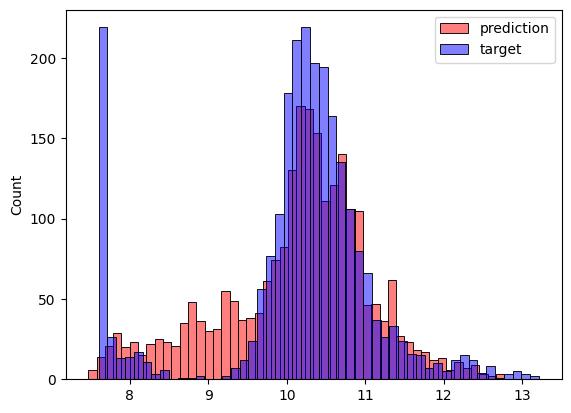

In [45]:
sns.histplot(y_pred, label='prediction', color='red', alpha=0.5, bins=50)
sns.histplot(y_val, label='target', color='blue', alpha=0.5, bins=50)
plt.legend()
plt.show()

---
## Step 11: Categorical variables

**Goal:** use text-like columns (make, fuel type, ...) in a model that only understands numbers.

### 11.1 What is a categorical variable?

A variable whose values are **categories** (labels), not quantities. Typically strings: `make`, `model`, `engine_fuel_type`, `transmission_type`, `driven_wheels`, ...

**Tricky case:** `number_of_doors` holds the numbers 2, 3, 4. But "4 doors" isn't "twice as much as 2 doors". They are different *kinds* of cars, so it's categorical even though it looks numeric.

### 11.2 One-hot encoding

Create **one binary (0/1) column per category value**: 1 in the matching column, 0 elsewhere. Exactly one "hot" 1 per row, hence the name.

| number_of_doors | num_doors_2 | num_doors_3 | num_doors_4 |
|:--:|:--:|:--:|:--:|
| 2 | 1 | 0 | 0 |
| 3 | 0 | 1 | 0 |
| 4 | 0 | 0 | 1 |
| 2 | 1 | 0 | 0 |

Let's build it on a tiny example first:

In [46]:
tiny = pd.DataFrame({'number_of_doors': [2, 3, 4, 2]})

print(tiny.number_of_doors == 2)                  # True / False per row
print((tiny.number_of_doors == 2).astype(int))    # 1 / 0 per row

for v in [2, 3, 4]:
    # 'num_doors_%s' % v is a string template -> num_doors_2, num_doors_3, ...
    tiny['num_doors_%s' % v] = (tiny.number_of_doors == v).astype('int')

tiny

0     True
1    False
2    False
3     True
Name: number_of_doors, dtype: bool
0    1
1    0
2    0
3    1
Name: number_of_doors, dtype: int64


,number_of_doors,num_doors_2,num_doors_3,num_doors_4
0,2,1,0,0
1,3,0,1,0
2,4,0,0,1
3,2,1,0,0


### 11.3 Add doors to `prepare_X`

Two details:

- We copy the DataFrame (so we don't write new columns into the user's data).
- We copy the `base` list: if we called `append` on `base` itself, it would grow every time the function runs.

In [47]:
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    df['age'] = 2017 - df.year
    features.append('age')

    for v in [2, 3, 4]:
        df['num_doors_%s' % v] = (df.number_of_doors == v).astype('int')
        features.append('num_doors_%s' % v)

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [48]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)           # about 0.5158 (was 0.5172)

np.float64(0.5157995641501902)

Only a tiny improvement: the number of doors isn't that useful.

### 11.4 Add the most popular makes

`make` has 48 values, so we take only the 5 most frequent:

- `value_counts()` counts how often each value appears (sorted high → low).
- `.head()` keeps the top 5; `.index` holds their names.

In [49]:
df_train.make.value_counts().head()

make
Chevrolet     667
Ford          519
Volkswagen    489
Toyota        452
Dodge         367
Name: count, dtype: int64

In [50]:
makes = list(df_train.make.value_counts().head().index)
makes

['Chevrolet', 'Ford', 'Volkswagen', 'Toyota', 'Dodge']

In [51]:
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    df['age'] = 2017 - df.year
    features.append('age')

    for v in [2, 3, 4]:
        df['num_doors_%s' % v] = (df.number_of_doors == v).astype('int')
        features.append('num_doors_%s' % v)

    for v in makes:
        df['make_%s' % v] = (df.make == v).astype('int')
        features.append('make_%s' % v)

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X


X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)           # about 0.508: roughly 1% better

np.float64(0.5076038849554877)

(`model` is skipped on purpose: 914 values would create 914 columns.)

### 11.5 Do it for all categorical columns

We collect the 5 most common values of each categorical column in a **dictionary**: `{column_name: [top values]}`.

In [52]:
categorical_variables = [
    'make', 'engine_fuel_type', 'transmission_type', 'driven_wheels',
    'market_category', 'vehicle_size', 'vehicle_style'
]

categories = {}

for c in categorical_variables:
    categories[c] = list(df_train[c].value_counts().head().index)

categories

{'make': ['Chevrolet', 'Ford', 'Volkswagen', 'Toyota', 'Dodge'],
 'engine_fuel_type': ['regular unleaded',
  'premium unleaded (required)',
  'premium unleaded (recommended)',
  'flex-fuel (unleaded/E85)',
  'diesel'],
 'transmission_type': ['AUTOMATIC',
  'MANUAL',
  'AUTOMATED_MANUAL',
  'DIRECT_DRIVE',
  'UNKNOWN'],
 'driven_wheels': ['front wheel drive',
  'rear wheel drive',
  'all wheel drive',
  'four wheel drive'],
 'market_category': ['Crossover',
  'Flex Fuel',
  'Luxury',
  'Hatchback',
  'Luxury,Performance'],
 'vehicle_size': ['Compact', 'Midsize', 'Large'],
 'vehicle_style': ['Sedan',
  '4dr SUV',
  'Coupe',
  'Convertible',
  '4dr Hatchback']}

In `prepare_X` we need **two loops**: the outer one over the dictionary's key-value pairs, the inner one over the values of each category.

> ⚠️ **The next two cells break the model on purpose.** Watch the RMSE.

In [53]:
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    df['age'] = 2017 - df.year
    features.append('age')

    for v in [2, 3, 4]:
        df['num_doors_%s' % v] = (df.number_of_doors == v).astype('int')
        features.append('num_doors_%s' % v)

    for c, values in categories.items():
        for v in values:
            df['%s_%s' % (c, v)] = (df[c] == v).astype('int')
            features.append('%s_%s' % (c, v))

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [54]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
print("validation RMSE:", rmse(y_val, y_pred))     # MUCH worse than 0.5!
print("biggest weight: ", np.abs(w).max())          # absurdly large

validation RMSE: 28.478764165331985
biggest weight:  1428487828478333.0


### 11.6 Something went wrong

Before, RMSE was about 0.5. Now it is far higher, and some weights are astronomically large. We added information, yet the model got *worse*. The next step explains why and how to fix it.

> **Why we split the data:** because we have a validation set, we noticed the problem immediately.
>
> The exact bad number can differ from machine to machine (you may see 41, or something else). It's numerically unstable, so the exact value isn't important. What matters is that it is **terrible**.

---
## Step 12: Regularization (fixing the broken model)

**Goal:** understand the huge-weights problem and fix it by adding a small number to a matrix.

### 12.1 The weak spot: the inverse

The normal equation needs `(XᵀX)⁻¹`. **Not every square matrix has an inverse.**

An inverse fails to exist when one column of `X` is a **duplicate**, or more generally a **linear combination**, of other columns.

> *Linear combination, in plain words:* a column you can build by adding up (scaled) copies of other columns. Example: if `c = 0.2·a + 0.5·b`, then `c` adds no new information, and the matrix is "singular" (no inverse).

A small matrix whose 2nd and 3rd columns are identical:

In [55]:
X_dup = np.array([
    [4, 4, 4],
    [3, 5, 5],
    [5, 1, 1],
    [5, 4, 4],
    [7, 5, 5],
    [4, 5, 5],
])

XTX_dup = X_dup.T.dot(X_dup)
XTX_dup          # note: its 2nd and 3rd columns are identical too

array([[140, 111, 111],
       [111, 108, 108],
       [111, 108, 108]])

In [56]:
# EXPECTED TO FAIL: a matrix with duplicate columns has no inverse
try:
    np.linalg.inv(XTX_dup)
except np.linalg.LinAlgError as e:
    print("Error:", e)

Error: Singular matrix


### 12.2 Why real data breaks things even without an error

Real data is noisy. A duplicate may show up as `5` vs `5.0001` (the lesson used an even tinier difference; the effect is the same, and a larger one is more reliable across computers). Now the columns are *almost* identical. NumPy **can** compute an inverse, but it contains **gigantic numbers** (~10¹⁴), and the weights of those near-duplicate columns become huge (like +3.4 million and −3.4 million that almost cancel out).

In [57]:
X_noisy = np.array([
    [4, 4, 4],
    [3, 5, 5],
    [5, 1, 1],
    [5, 4, 4],
    [7, 5, 5],
    [4, 5, 5.0001],            # a tiny difference!
])
y_small = [1, 2, 3, 1, 2, 1]

XTX_n = X_noisy.T.dot(X_noisy)
XTX_n_inv = np.linalg.inv(XTX_n)

print("inverse (huge numbers):\n", XTX_n_inv)

w_n = XTX_n_inv.dot(X_noisy.T).dot(y_small)
print("weights:", w_n)         # huge weights for the duplicated columns

inverse (huge numbers):
 [[ 4.12730055e-02 -6.11682842e+02  6.11637591e+02]
 [-6.11682842e+02  1.39187393e+08 -1.39186120e+08]
 [ 6.11637591e+02 -1.39186120e+08  1.39184847e+08]]
weights: [ 4.13226485e-01  2.55089673e+03 -2.55097629e+03]


> **Where do near-duplicates come from in our project?** One-hot columns are a classic source. For example `num_doors_2 + num_doors_3 + num_doors_4` equals 1 for every car with a known door count, which is the same as the bias column of ones (it differs only for the few cars with missing doors). Similar overlaps exist for other categories. *(This explanation is an addition to the lesson, which only says "duplicate or near-duplicate columns".)*

### 12.3 The fix: add a small number to the diagonal

Add a small value to the **diagonal** of `XᵀX` before inverting. Intuition: it makes it impossible for one column to be a perfect copy of another, so an inverse exists and its numbers stay moderate.

- `np.eye(k)` = the k×k identity matrix (ones on the diagonal).
- `0.01 * np.eye(k)` = 0.01 on the diagonal, zeros elsewhere.

This technique is called **regularization** (it *regulates* the weights so they can't blow up). The exact version used here is called **Ridge regression**. The size of the number is a **hyperparameter** called `r`. Bigger `r` → smaller, tamer weights.

Same small matrix as in the lesson. First with tiny noise (inverse has giant numbers), then after adding to the diagonal:

In [58]:
XTX_small = np.array([
    [1, 2, 2],
    [2, 1, 1.0000001],
    [2, 1.0000001, 1],
])

print("inverse without regularization:\n", np.linalg.inv(XTX_small))

XTX_small_reg = XTX_small + 0.01 * np.eye(3)
print("\ninverse WITH regularization (r = 0.01):\n", np.linalg.inv(XTX_small_reg))

inverse without regularization:
 [[-3.33333356e-01  3.33333339e-01  3.33333339e-01]
 [ 3.33333339e-01 -5.00000008e+06  4.99999991e+06]
 [ 3.33333339e-01  4.99999991e+06 -5.00000008e+06]]

inverse WITH regularization (r = 0.01):
 [[ -0.33668908   0.33501399   0.33501399]
 [  0.33501399  49.91590897 -50.08509104]
 [  0.33501399 -50.08509104  49.91590897]]


Same matrix, but the numbers in the inverse dropped from millions to small values.

### 12.4 Regularized training function

Everything stays the same except **one line**: after computing the Gram matrix, we add `r` to its main diagonal.

In [59]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])      # <- the only new line

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

### 12.5 Result

In [60]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression_reg(X_train, y_train, r=0.01)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
print("validation RMSE:", rmse(y_val, y_pred))     # about 0.46
print("biggest weight: ", np.abs(w).max())          # now tame

validation RMSE: 0.4565219900991152
biggest weight:  2.6193360542413275


From a broken model to about **0.46**, better even than before we added the categorical variables (0.508).

### The trade-off to remember

| `r` | Effect |
|---|---|
| `r = 0` | Plain regression. Can explode. |
| small `r` | Weights are tamed, the model is stable. |
| very large `r` | Weights squeezed too hard → the model gets worse. |

---
## Step 13: Tuning the model

**Goal:** pick the best `r` using the validation set. *Tuning = trying different hyperparameter values and keeping the one with the best **validation** score.* (We never tune on the test set.)

In [61]:
X_train = prepare_X(df_train)
X_val = prepare_X(df_val)

for r in [0.0, 0.00001, 0.0001, 0.001, 0.1, 1, 10]:
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)

    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)

    print(r, w0, score)

0.0 -2577834190335544.0 28.478764165331985
1e-05 7.0900029899944315 0.45651703947670436
0.0001 6.299215543191236 0.45651706204354375
0.001 6.286039235250088 0.4565175087711598
0.1 6.191208702212858 0.4565692763008546
1 5.6348966677267365 0.45722043179966637
10 4.283980108967508 0.4701456932099909


What you should see:

- `r = 0`: a huge bias and a huge RMSE (the broken model).
- Even a tiny `r`: the score recovers immediately.
- Scores stay about the same for small values, then slowly get worse as `r` grows. At 10 it's clearly worse.
- The bias term shrinks as `r` grows.

**Choice: `r = 0.001`.** It doesn't hurt performance and isn't extreme. Several nearby values work equally well, so don't agonize over it.

In [62]:
r = 0.001
w0, w = train_linear_regression_reg(X_train, y_train, r=r)

y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)       # about 0.46 (0.4565 in our run)

np.float64(0.4565175087711598)

---
## Step 14: The final model and using it

**Goal:** train on all available data, check once on the test set, and predict the price of a new car.

### 14.1 Combine train + validation

All settings are chosen, so we no longer need a separate validation set. More data = a better model.

- `pd.concat` joins DataFrames; `np.concatenate` joins arrays (arrays have no index to fix).

In [63]:
df_full_train = pd.concat([df_train, df_val])
df_full_train = df_full_train.reset_index(drop=True)

X_full_train = prepare_X(df_full_train)
y_full_train = np.concatenate([y_train, y_val])

print(X_full_train.shape, y_full_train.shape)

(9532, 41) (9532,)


### 14.2 Train the final model

In [64]:
w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)
print("bias:", w0)
print("number of weights:", len(w))

bias: 6.323067268384876
number of weights: 41


### 14.3 One final check on the test set

This is the **first and only time** we touch the test set.

In [65]:
X_test = prepare_X(df_test)
y_pred = w0 + X_test.dot(w)
rmse(y_test, y_pred)       # about 0.45-0.46 (0.4518 in our run)

np.float64(0.45177493100011545)

About 0.45 on test vs. about 0.46 on validation (0.4518 vs 0.4565 in our run): very close. The model **generalizes well**; the validation score wasn't a lucky accident.

### 14.4 Predict the price of one car

In real life, a website sends the car's data (as a dictionary) and the model answers with a price. We take a car from the test set and *pretend* it's new (fine, because the model never trained on it).

In [66]:
car = df_test.iloc[20].to_dict()
car

{'make': 'Toyota',
 'model': 'Sienna',
 'year': 2015,
 'engine_fuel_type': 'regular unleaded',
 'engine_hp': 266.0,
 'engine_cylinders': 6.0,
 'transmission_type': 'AUTOMATIC',
 'driven_wheels': 'front wheel drive',
 'number_of_doors': 4.0,
 'market_category': nan,
 'vehicle_size': 'Large',
 'vehicle_style': 'Passenger Minivan',
 'highway_mpg': 25,
 'city_mpg': 18,
 'popularity': 2031}

`prepare_X` expects a DataFrame, so we build a one-row DataFrame from a list containing the dictionary.

In [67]:
df_small = pd.DataFrame([car])
X_small = prepare_X(df_small)

y_pred = w0 + X_small.dot(w)       # an array with one number
y_pred = y_pred[0]                 # take that number
y_pred                             # this is the LOG price

np.float64(10.462651696973985)

In [68]:
print("predicted price: ", np.expm1(y_pred))       # back to dollars
print("actual price:    ", np.expm1(y_test[20]))

predicted price:  34983.19604673022
actual price:     35000.00000000001


In our run the prediction was very close to the real price. In the original lesson it was about $41,500 vs. $35,000. Individual predictions vary with the exact split, so don't read too much into one car; the RMSE over many cars is the fair measure.

### 🎉 You've built the full pipeline

```
data → clean → explore → split → features → train (normal equation + regularization)
     → validate (RMSE) → tune r → final model → test once → predict new cars
```

---
## Part 15: Cheat sheets

### 15.1 Formulas

| Name | Formula |
|---|---|
| Linear regression (one car) | `g(xi) = w0 + Σ wj · xij` |
| Vector form | `g(xi) = w0 + xiᵀ w` |
| Matrix form (with a column of ones) | `y ≈ X w` |
| Normal equation | `w = (XᵀX)⁻¹ Xᵀ y` |
| Regularized normal equation | `w = (XᵀX + r·I)⁻¹ Xᵀ y` |
| RMSE | `sqrt( mean( (prediction − actual)² ) )` |
| Log transform of the target | `y = log(price + 1)` → `np.log1p` |
| Back to dollars | `price = exp(y) − 1` → `np.expm1` |

### 15.2 pandas

| Code | Meaning |
|---|---|
| `pd.read_csv(path)` | Read a CSV into a DataFrame |
| `df.head()` | First 5 rows |
| `df.columns` | Column names |
| `df.columns.str.lower().str.replace(' ', '_')` | Clean the names |
| `df.dtypes` | Type of every column |
| `df[col].unique()` / `.nunique()` | Distinct values / how many |
| `df.isnull().sum()` | Missing values per column |
| `df.fillna(0)` | Replace missing with 0 |
| `df.iloc[a:b]` | Rows by position |
| `df.reset_index(drop=True)` | Renumber rows 0, 1, 2, ... |
| `del df[col]` | Delete a column |
| `df.copy()` | Make an independent copy |
| `df[col].value_counts()` | Count of each value |
| `(df[col] == v).astype(int)` | One-hot column (1/0) |
| `pd.concat([df1, df2])` | Stack two DataFrames |
| `df.iloc[i].to_dict()` | One row as a dictionary |
| `pd.DataFrame([dict])` | One-row DataFrame |
| `.values` | Convert to a NumPy array |

### 15.3 NumPy

| Code | Meaning |
|---|---|
| `np.arange(n)` | `[0, 1, ..., n-1]` |
| `np.random.seed(k)` | Make randomness repeatable |
| `np.random.shuffle(a)` | Shuffle an array in place |
| `np.log1p(x)` / `np.expm1(x)` | `log(x+1)` / its inverse |
| `np.ones(k)` | Array of k ones |
| `np.column_stack([a, B])` | Put arrays side by side as columns |
| `X.T` | Transpose |
| `A.dot(B)` | Matrix / vector multiplication |
| `np.linalg.inv(A)` | Matrix inverse |
| `np.eye(k)` | k×k identity matrix |
| `np.concatenate([a, b])` | Join two arrays |
| `np.sqrt`, `.mean()` | Square root, average |

### 15.4 Plotting

| Code | Meaning |
|---|---|
| `sns.histplot(series, bins=50)` | Histogram |
| `alpha=0.5` | Transparency (to overlay two histograms) |
| `%matplotlib inline` | Show plots in the notebook |

### 15.5 Scoreboard: how the model improved

| Model | Validation RMSE | Notes |
|---|---:|---|
| Baseline (5 numeric features) | ≈ 0.762 | First attempt |
| *(Numbers from the original lessons; yours may differ in the 2nd-3rd decimal.)* | | |
| + `age` | ≈ 0.517 | Biggest single gain |
| + number of doors | ≈ 0.516 | Almost no change |
| + top-5 makes | ≈ 0.508 | ~1% better |
| + all top-5 categories (no regularization) | **huge** | Broke the model |
| + regularization (`r = 0.01`) | ≈ 0.46 | Fixed, and best so far |
| Tuned (`r = 0.001`) | ≈ 0.46 | Chosen setting |
| Final model on **test** | ≈ 0.45-0.46 | Close to validation |

---
## Part 16: Common confusions (FAQ)

**Q1. Why do we predict the log of the price instead of the price?**
A long tail of very expensive cars confuses the model. Taking the log makes the price distribution bell-shaped, which works much better. We convert back with `np.expm1` when we want dollars.

**Q2. `log` vs `log1p`: what's the difference?**
`log1p(x) = log(x + 1)`. It is safe when `x = 0`. `expm1` undoes it.

**Q3. What is the difference between "the model" and "the weights"?**
The model is the *formula* (`w0 + Σ wj·xj`). The weights are the *numbers* inside it. The formula is fixed; training finds the numbers.

**Q4. Why is there a column of ones in `X`?**
It lets the bias term `w0` be treated like any other weight (`w0 × 1`), so predicting for all cars is one clean multiplication `X.dot(w)`.

**Q5. Why can't we just compute `w = X⁻¹ y`?**
`X` isn't square, so it has no inverse. We use `XᵀX` (square) and get the closest possible solution.

**Q6. The solution is "approximate". Is the model wrong?**
Real data doesn't sit perfectly on a straight line, so no weights can match every price exactly. We pick the weights with the smallest overall error. That is normal in ML.

**Q7. Why three data sets, not just train/test?**
The validation set is for *choosing* things (features, `r`). If we choose using the test set, we "use it up" and its final score becomes too optimistic. The test set is the final, once-only exam.

**Q8. Why train the final model on train + validation?**
After tuning is done, extra data makes the model better. The test set stays untouched for the final check.

**Q9. Why is RMSE on train similar to RMSE on validation here? Isn't validation usually worse?**
Usually validation is somewhat worse. Here the model is simple (linear), so it can't memorize the training set and the two scores are close. A large gap would signal overfitting.

**Q10. What is "numerical instability"?**
Tiny differences or nearly duplicated columns make some calculations produce gigantic, unreliable numbers. Regularization keeps them under control.

**Q11. Why did adding more features make the model worse in Step 11?**
Not because the information was bad, but because the new one-hot columns created near-duplicate / linearly dependent columns, making `XᵀX` nearly non-invertible and the weights explode (Step 12).

**Q12. Feature vs. weight?**
A feature is *data* about a car (horsepower = 453). A weight is a *learned number* for a feature (0.01 per horsepower).

**Q13. Why `copy()` inside `prepare_X`?**
So the function doesn't modify the DataFrame you pass in (no hidden side effects). Likewise `base.copy()` so we don't keep appending to the original list.

**Q14. Why is filling missing values with 0 acceptable?**
A feature of 0 contributes nothing to the sum, so the model ignores it for that car. It's simple, though not always best. Filling with the column mean is often more reasonable.

**Q15. Is `r` learned automatically?**
No. `r` is a hyperparameter *we* choose by trying several values and checking validation RMSE.

**Q16. `X.dot(w)` vs `w0 + X.dot(w)`?**
If `X` has a column of ones and `w` includes `w0` → `X.dot(w)`. If `X` is the *plain* feature matrix and `w0` is separate (as our training functions return) → `w0 + X.dot(w)`. Same result.

**Q17. Why do my numbers differ slightly from the lessons?**
Different NumPy/pandas versions or a different seed can change the shuffle, and the broken (unregularized) model is numerically unstable. Small differences are normal. What matters is the pattern: baseline > age > categories (broken) > regularized.

**Q18. Small inconsistencies in the original lesson notes.**
Some short notes use `w0 = 7.1` and say "inverse function `exp()`", while the lesson uses `w0 = 7.17` and `np.expm1`. Use the lesson versions: they pair correctly with `log1p`.

---
## Part 17: Self-test questions (with answers)

Try each question first, then click the arrow to reveal the answer.

**1. Is predicting a car's price regression or classification?**
<details><summary>Answer</summary>Regression: the output is a number.</details>

**2. Name the three data splits and the job of each.**
<details><summary>Answer</summary>Train: learn the weights. Validation: choose models/settings. Test: a single final check.</details>

**3. Why do we shuffle before splitting?**
<details><summary>Answer</summary>The data may be ordered (here by make); shuffling prevents a biased split.</details>

**4. What does `np.random.seed(2)` do?**
<details><summary>Answer</summary>Makes the random shuffle reproducible.</details>

**5. Why do we remove `msrp` from the features?**
<details><summary>Answer</summary>To avoid target leakage (predicting the price from the price).</details>

**6. Why apply `log1p` to the target?**
<details><summary>Answer</summary>It removes the long tail so the target is closer to a normal distribution, which works better for modelling.</details>

**7. Weights `w0 = 2, w = [0.5, 3]`, car `x = [10, 1]`. What's the prediction?**
<details><summary>Answer</summary>2 + 0.5·10 + 3·1 = 10.</details>

**8. What is the shape of `XᵀX` if `X` is 7,000 × 10?**
<details><summary>Answer</summary>10 × 10.</details>

**9. Write the normal equation.**
<details><summary>Answer</summary>w = (XᵀX)⁻¹ Xᵀ y</details>

**10. Compute the RMSE for predictions `[2, 4]` and actual `[1, 6]`.**
<details><summary>Answer</summary>Errors 1 and −2 → squares 1 and 4 → mean 2.5 → sqrt ≈ 1.58.</details>

**11. Why is RMSE on the training data not a good way to judge a model?**
<details><summary>Answer</summary>The model has seen that data, so the score is optimistic. Use validation data.</details>

**12. What is one-hot encoding? Encode `[red, blue, red]`.**
<details><summary>Answer</summary>One binary column per category: red = [1, 0, 1], blue = [0, 1, 0].</details>

**13. Why did RMSE explode after adding all categorical features?**
<details><summary>Answer</summary>Near-duplicate / linearly dependent columns made XᵀX almost non-invertible, producing giant weights.</details>

**14. What does regularization do here?**
<details><summary>Answer</summary>Adds r to the diagonal of XᵀX, so it is safely invertible and the weights stay small.</details>

**15. What happens if `r` is too large?**
<details><summary>Answer</summary>The weights are squeezed too much and the model gets worse.</details>

**16. How do you convert a model output of 10.63 into dollars?**
<details><summary>Answer</summary>np.expm1(10.63) ≈ 41,000.</details>

**17. Why use the test set only at the end?**
<details><summary>Answer</summary>So its score is an honest estimate of performance on new data.</details>

---
## Part 18: Practice ideas

1. **Include 10 values instead of 5** for each categorical variable (the course's own suggested exercise). Does validation RMSE improve? Do you need a different `r`?
2. **Fill missing values with the mean** instead of 0 (compute the mean on the *training* data only, then reuse it for validation and test). Compare RMSE.
3. **Plot predictions vs. actual** (overlaid histograms) for the final model on the validation data.
4. **Try other datasets** for regression practice:
   - [California housing](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_california_housing.html): predict house prices
   - [Student Performance](https://archive.ics.uci.edu/ml/datasets/Student+Performance): predict student performance
   - [UCI regression datasets](https://archive.ics.uci.edu/ml/datasets.php?task=reg)

Use the cell below as a scratch pad.

In [69]:
# Your experiments here

### One-paragraph summary to remember

> We want to predict car prices. We clean and explore the data, notice the price has a long tail and **log-transform** it, and **split** the data into train/validation/test. Linear regression predicts with `w0 + Σ wj·xj`, which for all cars is just `X·w`. The weights come from the **normal equation** `w = (XᵀX)⁻¹Xᵀy`. We measure quality with **RMSE** on the **validation** set. We improve the model with **feature engineering** (age) and **one-hot encoded categorical variables**. When near-duplicate columns break the matrix inverse, **regularization** (adding `r` to the diagonal) fixes it. We **tune** `r`, train the final model on train + validation, check once on test, and use `np.expm1` to turn log-predictions back into dollars.